# CEE 902 · Multiclass Weather Classification with Softmax Regression

**Author:** Samuel Asiedu

Classify the weather as **Sunny, Rain, or Snow** from temperature and relative humidity, using **100 synthetic observations**. The data are for learning purposes and are not suitable for real forecasting.

The model follows three steps: **(1) define the model, (2) define the cost function $J$, (3) minimize $J$ with gradient descent**.

The data file is expected at `data/CEE902_weather_synthetic_100.csv`.

## 1. Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

DATA_FILE = "data/CEE902_weather_synthetic_100.csv"
FEATURE_COLS = ["Temperature_C", "Humidity_pct"]
CLASSES = ["Sunny", "Rain", "Snow"]          # lecture order: 1 = Sunny, 2 = Rain, 3 = Snow
COLORS = {"Sunny": "#E4A53C", "Rain": "#3478BC", "Snow": "#33A7B5"}
MARKERS = {"Sunny": "o", "Rain": "s", "Snow": "^"}

data = pd.read_csv(DATA_FILE)
print("Dataset shape:", data.shape)
print("\nFirst five observations:")
print(data.head())
print("\nClass counts:")
print(data["Weather"].value_counts())
print("\nMissing values:")
print(data.isna().sum())

Dataset shape: (100, 3)

First five observations:
   Temperature_C  Humidity_pct Weather
0           22.4          50.1   Sunny
1           -4.6          70.0    Snow
2            8.8          84.1    Rain
3           21.2          94.7    Rain
4           20.2          80.8    Rain

Class counts:
Weather
Sunny    34
Snow     33
Rain     33
Name: count, dtype: int64

Missing values:
Temperature_C    0
Humidity_pct     0
Weather          0
dtype: int64


## 2. Initial visualization

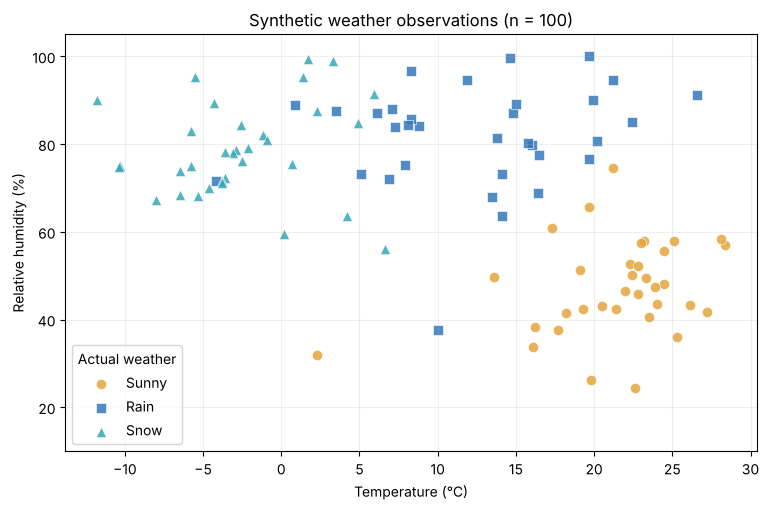

In [2]:
def plot_observations(ax):
    # Scatter the observations in the temperature-humidity plane, colored by actual weather.
    for weather in CLASSES:
        subset = data[data["Weather"] == weather]
        ax.scatter(subset["Temperature_C"], subset["Humidity_pct"],
                   c=COLORS[weather], marker=MARKERS[weather],
                   edgecolors="white", linewidths=0.5, s=55, alpha=0.85, label=weather)
    ax.set(xlabel="Temperature (°C)", ylabel="Relative humidity (%)")
    ax.grid(alpha=0.2)


fig, ax = plt.subplots(figsize=(7.8, 5.2))
plot_observations(ax)
ax.set_title("Synthetic weather observations (n = 100)")
ax.set_ylim(10, 105)
ax.legend(title="Actual weather")
plt.tight_layout()
plt.show()

### Observations before modeling

- **Sunny** is the easiest class to distinguish: it occupies the warm, dry region. **Rain** and **Snow** overlap at high humidity for temperatures of roughly 0 to 7 °C, so most errors are expected there.
- Neither feature **alone** separates all three classes. Humidity separates Sunny from the other two reasonably well, and temperature separates Snow from Rain, so both are needed.
- Softmax regression is linear in its inputs, so the boundary between any two classes is a **straight line** in this plane.

## 3. Prepare the inputs and class targets

- The two features are **standardized** (zero mean, unit standard deviation) to make gradient descent better conditioned. The training mean and standard deviation are stored for later use on new observations.
- A column of ones ($x_0 = 1$) is added for the intercepts, so `X` has shape $(m, 3)$.
- Each label is converted to a **one-hot** row of `Y`, also with shape $(m, 3)$. For example, Snow is `[0, 0, 1]`.

In [3]:
X_raw = data[FEATURE_COLS].to_numpy(dtype=float)
y = data["Weather"].to_numpy()
m = len(y)
assert not data.isna().any().any(), "The dataset contains missing values."
assert set(y) == set(CLASSES), "Unexpected class labels in the dataset."

feature_mean = X_raw.mean(axis=0)
feature_std = X_raw.std(axis=0)


def build_design_matrix(features_raw):
    # Standardize raw [temperature, humidity] rows with the training statistics and add x0 = 1.
    features_raw = np.asarray(features_raw, dtype=float).reshape(-1, len(FEATURE_COLS))
    features_scaled = (features_raw - feature_mean) / feature_std
    return np.column_stack([np.ones(len(features_scaled)), features_scaled])


X = build_design_matrix(X_raw)
y_index = np.array([CLASSES.index(label) for label in y])
Y = np.eye(len(CLASSES))[y_index]

print("X shape:", X.shape, "| Y shape:", Y.shape)
print(pd.DataFrame(Y[:5], columns=CLASSES))

X shape: (100, 3) | Y shape: (100, 3)
   Sunny  Rain  Snow
0    1.0   0.0   0.0
1    0.0   0.0   1.0
2    0.0   1.0   0.0
3    0.0   1.0   0.0
4    0.0   1.0   0.0


## 4. Softmax regression in three steps

### Step 1 · Define the model

For class $k = 1, 2, 3$ and observation $i$:

$$z_k^{(i)} = \sum_{j=0}^{2}\theta_{k,j}\,x_j^{(i)},
\qquad
h_{\theta,k}\big(\mathbf{x}^{(i)}\big) = p_k^{(i)} = \frac{e^{z_k^{(i)}}}{\sum_{r=1}^{3} e^{z_r^{(i)}}}$$

`theta[k, j]` stores the coefficient of feature $j$ for class $k$, so each **row** of `theta` belongs to one class. There are nine coefficients in total, including three intercepts. `Z = X @ theta.T` and `P` both have shape $(m, 3)$, and each row of `P` sums to one.

Subtracting each row's largest logit before exponentiation leaves the probabilities unchanged and prevents numerical overflow.

In [4]:
def softmax(Z):
    # Row-wise softmax with the maximum subtracted for numerical stability.
    Z_shift = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z_shift)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)


def model(theta, X):
    # Class probabilities, shape (m, 3), for coefficients theta of shape (3, 3).
    return softmax(X @ theta.T)


theta_initial = np.zeros((len(CLASSES), X.shape[1]))

# Check 1: logits [2, 1, 0] should give [0.665241, 0.244728, 0.090031].
print(np.round(softmax(np.array([[2.0, 1.0, 0.0]])), 6))
# Check 2: zero coefficients should give equal probabilities of 1/3.
print(np.round(model(theta_initial, X[:1]), 6))

[[0.665241 0.244728 0.090031]]
[[0.333333 0.333333 0.333333]]


### Step 2 · Define the categorical cross-entropy cost $J$

$$J(\theta) = -\frac{1}{m}\sum_{i=1}^{m}\sum_{k=1}^{3} y_k^{(i)}\,\log\Big(h_{\theta,k}\big(\mathbf{x}^{(i)}\big)\Big)$$

Only the actual class contributes for each observation, because the one-hot target is zero for the other classes. Probabilities are clipped away from zero to avoid `log(0)`.

In [5]:
def get_cost(theta, X, Y):
    # Mean categorical cross-entropy (a scalar).
    P = np.clip(model(theta, X), 1e-15, 1.0)
    return -np.sum(Y * np.log(P)) / X.shape[0]


# Check 1: zero coefficients give P = 1/3 everywhere, so J = -log(1/3) = 1.098612.
print(f"{get_cost(theta_initial, X, Y):.6f}")

# Check 2: one observation with logits [2, 1, 0] and actual class Snow,
# so J = -log(P(Snow)) = 2.407606.
X_example = np.array([[1.0, 0.0, 0.0]])
theta_example = np.array([[2.0, 0.0, 0.0],
                          [1.0, 0.0, 0.0],
                          [0.0, 0.0, 0.0]])
Y_example = np.array([[0.0, 0.0, 1.0]])
print(f"{get_cost(theta_example, X_example, Y_example):.6f}")

1.098612
2.407606


### Step 3 · Gradient descent

$$\frac{\partial J}{\partial\theta_{k,j}} = \frac{1}{m}\sum_{i=1}^{m}\big(p_k^{(i)} - y_k^{(i)}\big)\,x_j^{(i)},
\qquad
\theta_{k,j} := \theta_{k,j} - \alpha\,\frac{\partial J}{\partial\theta_{k,j}}$$

In matrix form the gradient is `(P - Y).T @ X / m`, with shape $(3, 3)$ to match `theta`. All coefficients are updated simultaneously from the same gradient.

J: 1.098612 -> 0.224929

Coefficients for standardized inputs:
       Intercept  Temperature (scaled)  Humidity (scaled)
Sunny    -1.4257                4.4957            -2.6958
Rain      2.1240                0.1413             1.2829
Snow     -0.6983               -4.6370             1.4129


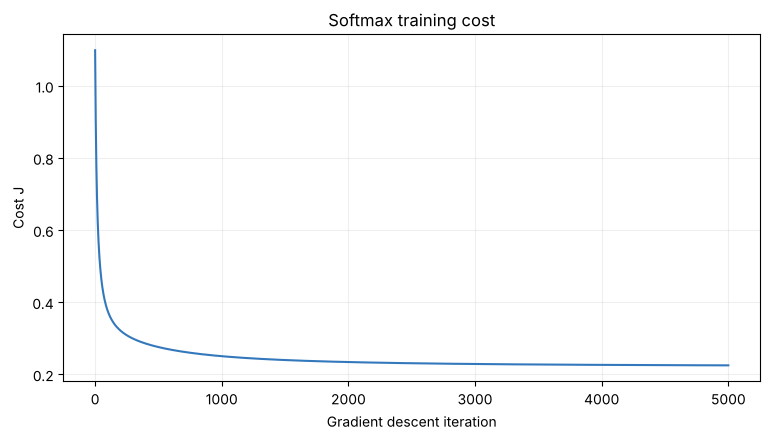

In [6]:
def gradient_descent(theta, X, Y, alpha=0.1, iterations=5000):
    # Batch gradient descent. Returns the fitted coefficients and the cost history,
    # which includes the initial cost and therefore has iterations + 1 entries.
    theta = theta.copy()
    J_history = [get_cost(theta, X, Y)]
    for _ in range(iterations):
        P = model(theta, X)
        gradient = (P - Y).T @ X / X.shape[0]
        theta = theta - alpha * gradient
        J_history.append(get_cost(theta, X, Y))
    return theta, np.array(J_history)


ALPHA = 0.1
ITERATIONS = 5000
theta, J_history = gradient_descent(theta_initial, X, Y, ALPHA, ITERATIONS)

print(f"J: {J_history[0]:.6f} -> {J_history[-1]:.6f}")
print("\nCoefficients for standardized inputs:")
print(pd.DataFrame(theta, index=CLASSES,
                   columns=["Intercept", "Temperature (scaled)", "Humidity (scaled)"]).round(4))

fig, ax = plt.subplots(figsize=(7.8, 4.5))
ax.plot(np.arange(ITERATIONS + 1), J_history, color="#3478BC")
ax.set(xlabel="Gradient descent iteration", ylabel="Cost J", title="Softmax training cost")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Predictions and evaluation

The predicted class is the one with the largest probability (`argmax`), so no separate probability threshold is needed. Accuracy and the confusion matrix below describe the fit to the **same 100 training observations** and do not estimate performance on unseen data.

Training accuracy: 91.0% (91/100)
 Temperature_C  Humidity_pct Weather  P(Sunny)  P(Rain)  P(Snow) Predicted
          22.4          50.1   Sunny    0.9930   0.0070   0.0000     Sunny
          -4.6          70.0    Snow    0.0000   0.0263   0.9737      Snow
           8.8          84.1    Rain    0.0006   0.8783   0.1211      Rain
          21.2          94.7    Rain    0.0085   0.9907   0.0008      Rain
          20.2          80.8    Rain    0.0943   0.9047   0.0010      Rain
          27.2          41.8   Sunny    0.9998   0.0002   0.0000     Sunny
          28.4          56.9   Sunny    0.9972   0.0028   0.0000     Sunny
          19.7         100.0    Rain    0.0016   0.9969   0.0015      Rain
          24.5          48.2   Sunny    0.9979   0.0021   0.0000     Sunny
          16.0          79.7    Rain    0.0250   0.9689   0.0061      Rain


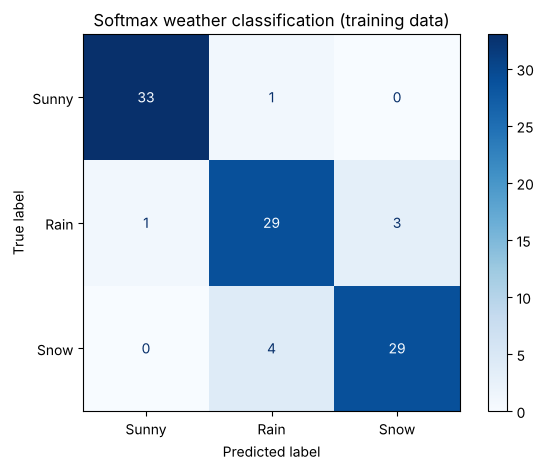

In [7]:
def predict_weather(features_raw):
    # Predicted labels and class probabilities for raw [Temperature_C, Humidity_pct] rows.
    probabilities = model(theta, build_design_matrix(features_raw))
    labels = np.array(CLASSES)[np.argmax(probabilities, axis=1)]
    return labels, probabilities


y_pred, P = predict_weather(X_raw)
accuracy = np.mean(y_pred == y)
print(f"Training accuracy: {accuracy:.1%} ({np.sum(y_pred == y)}/{m})")

results = data.copy()
for k, weather in enumerate(CLASSES):
    results[f"P({weather})"] = P[:, k]
results["Predicted"] = y_pred
print(results.head(10).round(4).to_string(index=False))

cm = confusion_matrix(y, y_pred, labels=CLASSES)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES).plot(cmap="Blues")
plt.title("Softmax weather classification (training data)")
plt.tight_layout()
plt.show()

In [8]:
errors_by_class = cm.sum(axis=1) - np.diag(cm)
print("Misclassified observations by actual class:")
print(pd.Series(errors_by_class, index=CLASSES))
print()
for k, actual in enumerate(CLASSES):
    for r, predicted in enumerate(CLASSES):
        if k != r and cm[k, r] > 0:
            print(f"Actual {actual}, predicted {predicted}: {cm[k, r]}")

Misclassified observations by actual class:
Sunny    1
Rain     4
Snow     4
dtype: int64

Actual Sunny, predicted Rain: 1
Actual Rain, predicted Sunny: 1
Actual Rain, predicted Snow: 3
Actual Snow, predicted Rain: 4


### Decision regions

The fitted model is evaluated on a grid of temperature and humidity values to show which class it predicts in each part of the feature space. Misclassified training observations are circled.

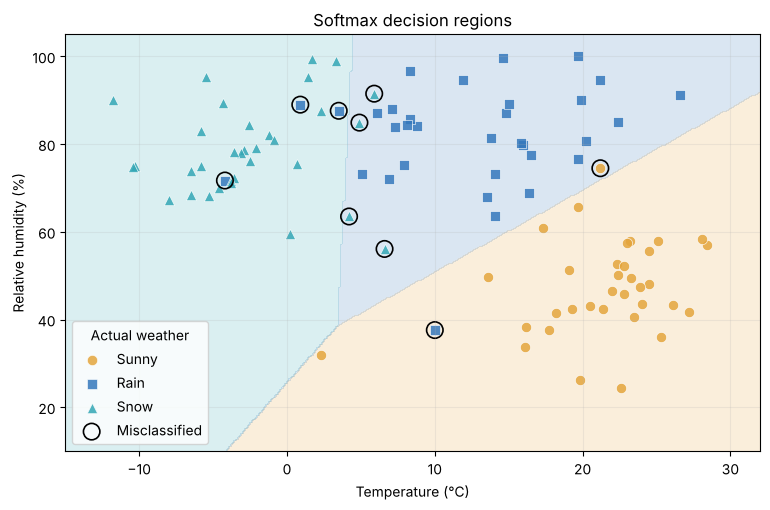

In [9]:
temp_grid, hum_grid = np.meshgrid(np.linspace(-15, 32, 300), np.linspace(10, 105, 300))
grid_labels, _ = predict_weather(np.column_stack([temp_grid.ravel(), hum_grid.ravel()]))
grid_index = np.array([CLASSES.index(label) for label in grid_labels]).reshape(temp_grid.shape)

fig, ax = plt.subplots(figsize=(7.8, 5.2))
ax.contourf(temp_grid, hum_grid, grid_index, levels=[-0.5, 0.5, 1.5, 2.5],
            colors=[COLORS[c] for c in CLASSES], alpha=0.18)
plot_observations(ax)
wrong = y_pred != y
ax.scatter(X_raw[wrong, 0], X_raw[wrong, 1], facecolors="none", edgecolors="black",
           s=140, linewidths=1.2, label="Misclassified")
ax.set_title("Softmax decision regions")
ax.legend(title="Actual weather", loc="lower left")
plt.tight_layout()
plt.show()

### Predict a new observation

In [10]:
new_observation = [[2.0, 85.0]]      # 2 °C and 85% relative humidity
new_label, new_P = predict_weather(new_observation)
print("Predicted weather:", new_label[0])
print(pd.DataFrame(new_P, columns=CLASSES).round(4))

Predicted weather: Snow
   Sunny    Rain    Snow
0    0.0  0.2866  0.7134


## 6. Interpretation

1. **Probability sums.** Softmax divides each positive exponential by the sum of all exponentials in its row, so the probabilities of each observation sum to one.
2. **Cost.** With $\alpha = 0.1$ and 5,000 iterations, $J$ decreases from 1.098612 to approximately 0.224929. If the cost increased instead, the gradient sign, the averaging by $m$, the simultaneous update, and the learning rate would be the first things to check.
3. **Confusion matrix.** Rows are actual classes and columns are predictions, in the order Sunny, Rain, Snow. Nine observations are misclassified, and seven of them are confusions between Rain and Snow, where the two classes overlap near 0 to 7 °C.
4. **Evaluation.** The 91% accuracy is measured on the same observations used to estimate the parameters, so it describes training fit. Performance on unseen observations requires separate evaluation data.